# Pronóstico semanal de casos de violencias basadas en género contra mujeres indígenas del Cauca
**Curso:** Deep Learning · **Taller ABP – Entrega 1**

Modelo recurrente (GRU/LSTM, PyTorch) que pronostica, a una semana, el número de casos registrados por zona del CRIC
(Observatorio de VBG – Programa Mujeres CRIC / AIC-EPSI, enero 2025 – mayo 2026).

> **Nota ética.** El archivo original contiene datos personales de víctimas y **no está en este repositorio**.
> Aquí solo se usan conteos agregados por semana y zona (`data/processed/`).

In [1]:
import sys, json, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
sys.path.insert(0, '../src')
from model import *
import evaluate as ev
torch.manual_seed(0); np.random.seed(0)
print('torch', torch.__version__)

torch 2.15.0+cu132


## 1. Datos
Serie semanal de casos por zona (6 canales: 5 zonas principales + `OTRAS`).

In [2]:
ser = load_series()
print(ser.shape, ser.index.min().date(), '->', ser.index.max().date())
display(ser.describe().round(2))
ser.sum().sort_values(ascending=False).to_frame('casos')

(73, 6) 2024-12-30 -> 2026-05-18


,CXHAB WALA KIWE,TIERRADENTRO,ORIENTE,SAT TAMA KIWE,SUR,OTRAS
count,73.00,73.00,73.00,73.00,73.00,73.00
mean,6.11,4.29,1.67,1.59,1.12,1.85
std,3.12,2.51,1.56,1.54,1.07,1.64
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,4.00,2.00,1.00,0.00,0.00,1.00
50%,6.00,4.00,1.00,1.00,1.00,1.00
75%,8.00,6.00,2.00,2.00,1.00,2.00
max,14.00,13.00,7.00,7.00,4.00,6.00


,casos
CXHAB WALA KIWE,446
TIERRADENTRO,313
OTRAS,135
ORIENTE,122
SAT TAMA KIWE,116
SUR,82


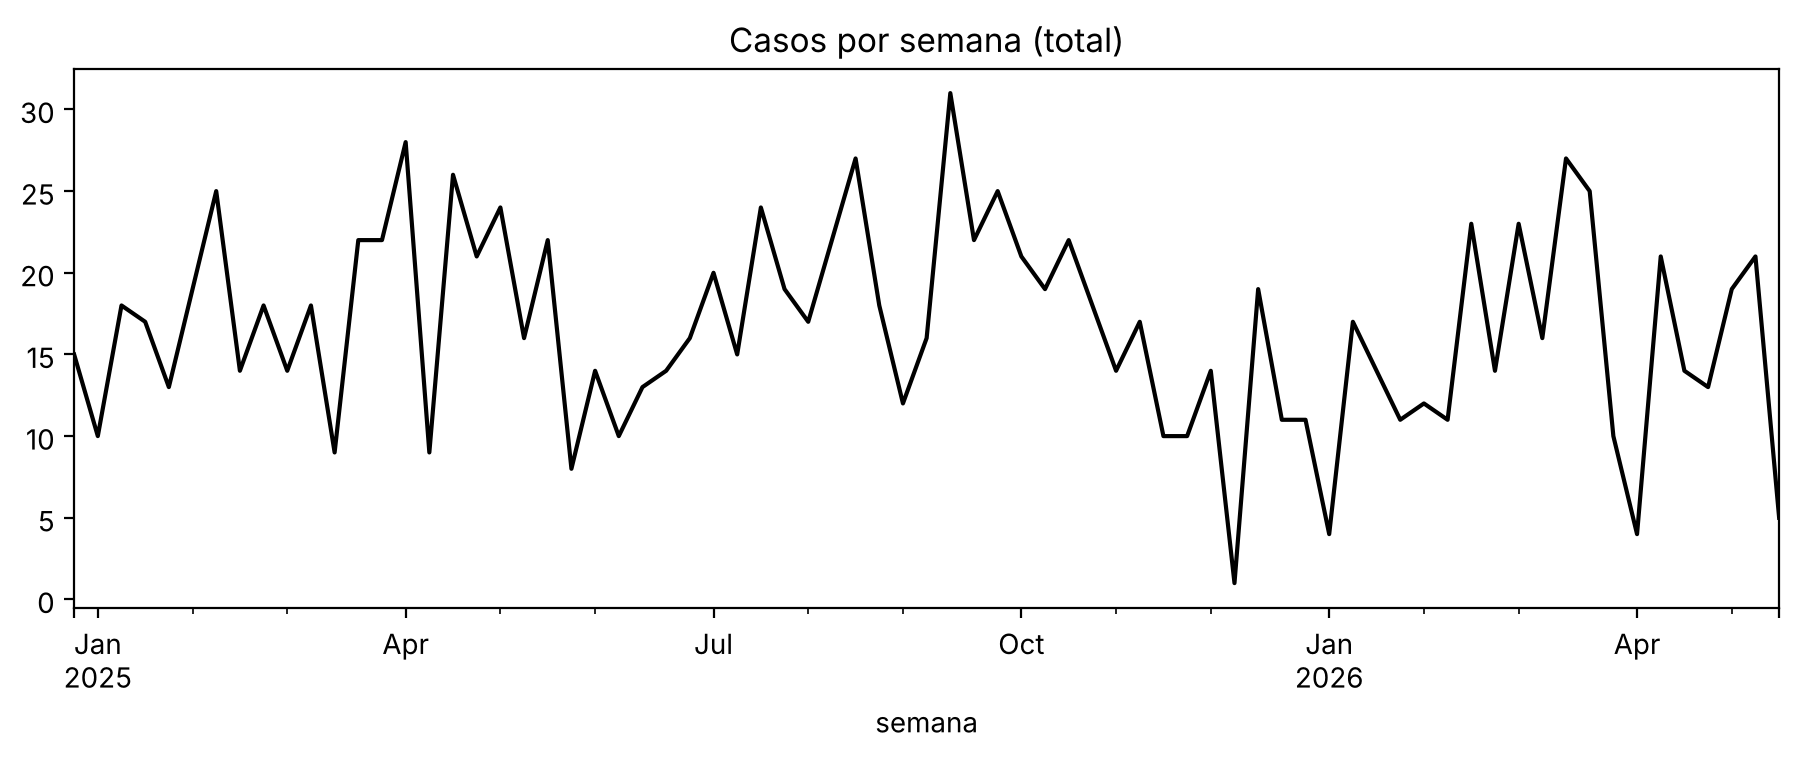

In [3]:
fig, ax = plt.subplots(figsize=(11,3.5)); ser.sum(axis=1).plot(ax=ax, color='k'); ax.set_title('Casos por semana (total)'); plt.show()

**Hallazgo de calidad de datos:** las semanas posteriores al 18-may-2026 están incompletas (rezago de registro) y se excluyeron;
también se descartaron 22 registros con fecha posterior al corte del boletín (30-jun-2026).

## 2. Ventanas deslizantes
Entrada: 8 semanas × 6 zonas. Objetivo: casos de la semana siguiente en cada zona.

In [4]:
X, y = make_windows(ser.values.astype(np.float32))
print('X', X.shape, 'y', y.shape)

X (65, 8, 6) y (65, 6)


## 3. Arquitectura
`log1p(conteos) → GRU(6→16) → Dropout(0.2) → Linear(16→6) → softplus` = **tasa λ de Poisson** por zona.
Pérdida: *Poisson NLL* (los datos son conteos pequeños, con muchos ceros). Optimizador AdamW, *early stopping* sobre validación temporal.

In [5]:
m = Forecaster(6, hidden=16, cell='gru'); print(m); print('parámetros:', sum(p.numel() for p in m.parameters()))

Forecaster(
  (rnn): GRU(6, 16, batch_first=True)
  (drop): Dropout(p=0.2, inplace=False)
  (head): Linear(in_features=16, out_features=6, bias=True)
)
parámetros: 1254


## 4. Entrenamiento (partición cronológica 60 / 20 / 20)

épocas: 79 | mejor val: 0.2621


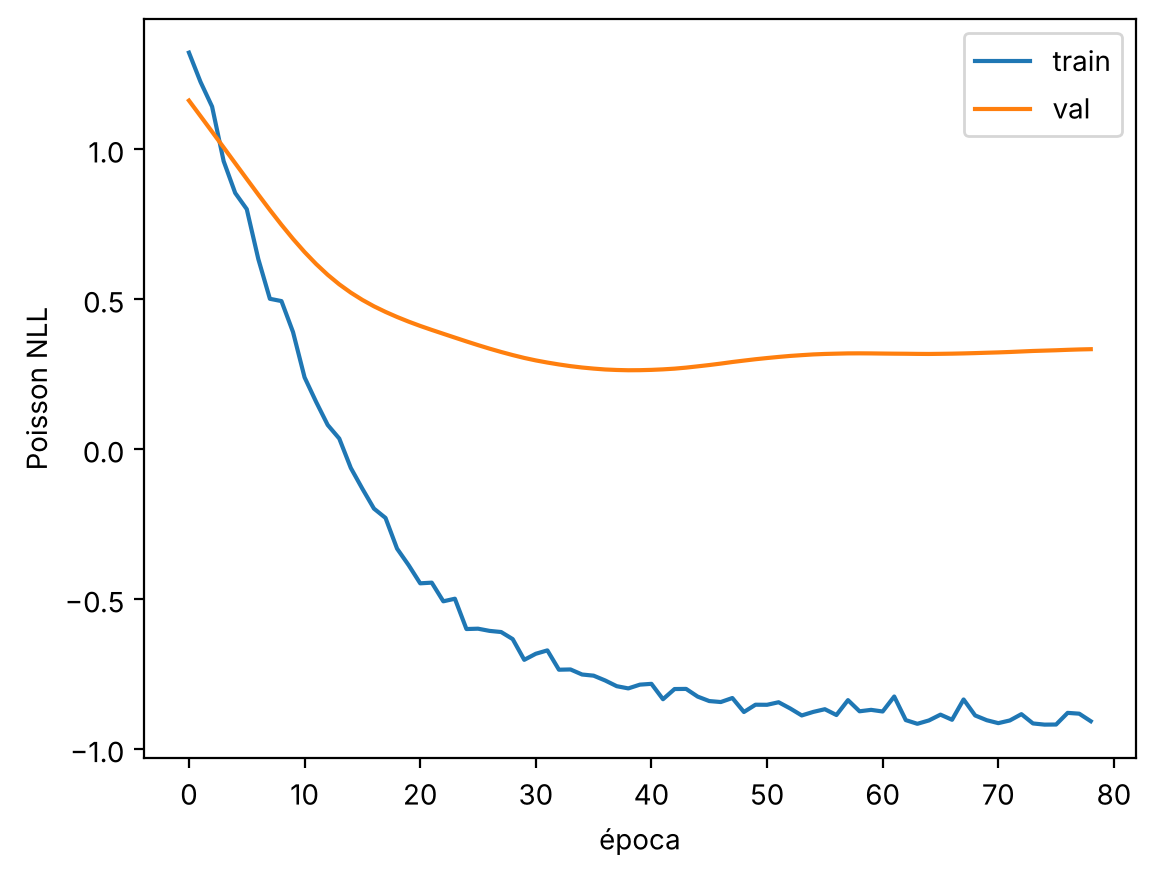

In [6]:
n = len(X); a, b = int(.6*n), int(.8*n)
model = fit(X[:a], y[:a], X[a:b], y[a:b], cell='gru', seed=0)
h = model.history; print('épocas:', len(h['train']), '| mejor val:', round(min(h['val']),4))
plt.plot(h['train'], label='train'); plt.plot(h['val'], label='val'); plt.xlabel('época'); plt.ylabel('Poisson NLL'); plt.legend(); plt.show()

## 5. Validación *walk-forward*
Con solo 73 semanas, una única partición es muy ruidosa. Se reentrena cada 5 semanas con ventana expansiva (5 semillas por modelo)
y se pronostica 1 semana adelante en 30 semanas de prueba. Se compara contra baselines simples.

In [7]:
ev.main()

                   MAE   RMSE  Poisson_dev  MAE_total
GRU              1.545  2.063        1.801      5.615
LSTM             1.544  2.070        1.803      5.632
ultima_semana    2.050  2.975       13.846      6.967
media_movil_4    1.600  2.207        2.075      5.217
media_movil_8    1.619  2.181        1.970      5.808
media_historica  1.578  2.134        1.844      5.863
MAE_total GRU - MM4: media 0.390 IC95 [-1.037, 1.696]


In [8]:
res = pd.read_csv('../reports/metricas_walk_forward.csv', index_col=0); res

,MAE,RMSE,Poisson_dev,MAE_total
GRU,1.545,2.063,1.801,5.615
LSTM,1.544,2.070,1.803,5.632
ultima_semana,2.050,2.975,13.846,6.967
media_movil_4,1.600,2.207,2.075,5.217
media_movil_8,1.619,2.181,1.970,5.808
media_historica,1.578,2.134,1.844,5.863


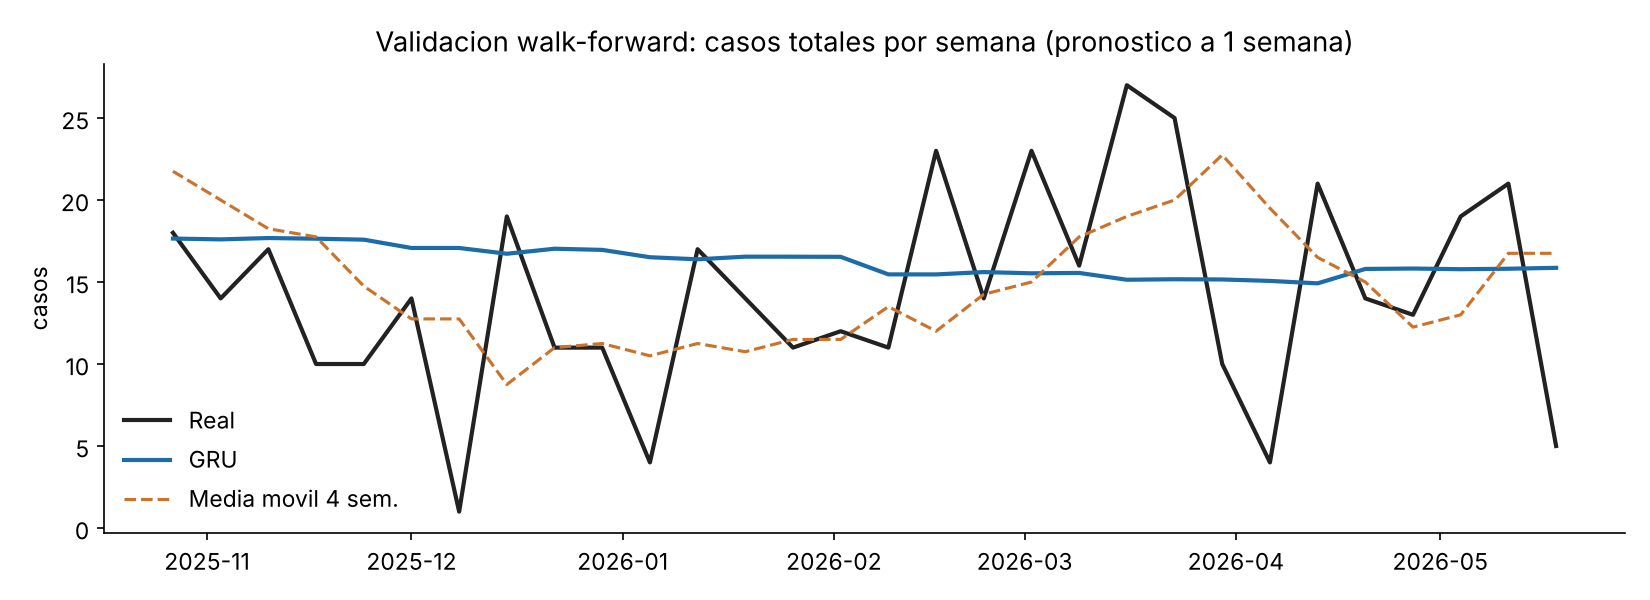

In [9]:
from IPython.display import Image; Image('../reports/figures/02_walk_forward_total.png')

## 6. Conclusiones y limitaciones
* El GRU y el LSTM mejoran marginalmente a los baselines en MAE por zona (≈1.54 vs 1.58) y devianza de Poisson (1.80 vs 1.84), pero **la diferencia no es estadísticamente concluyente** y en el total semanal la media móvil de 4 semanas es mejor.
* El modelo básicamente aprende el **nivel medio** por zona: con ~1.200 casos y 73 semanas, la dinámica semanal es en gran parte ruido de conteo.
* Son casos **registrados** (subregistro, miedo a denunciar, cobertura desigual de IPS): el modelo pronostica registros, no la violencia real.
* Uso previsto: apoyo a la planeación de recursos; **no** para focalizar o vigilar personas.